In [8]:
import sys
import os
from typing import NamedTuple
import math
import numpy as np
import scipy as sp
import pandas as pd
from matplotlib import pyplot as plt
import pickle


sys.path.append(os.path.join(os.getcwd(), '../'))
from utils_fly import read_utils

sys.path.append(os.path.join(os.getcwd(), '../../../../'))
from utils import plot_utils
from utils import train_utils
from models import bom_ss as bom
from models import hgm_ss as hgm

In [9]:
import importlib
importlib.reload(read_utils)
importlib.reload(plot_utils)
importlib.reload(train_utils)
importlib.reload(bom)
importlib.reload(hgm)

<module 'models.hgm_ss' from '/home/julian-zim/Files/Cloud/OneDrive/OneFiles/Linux/ZimmerLab/MSc_Thesis/Workspace/hobe/models/hgm_ss.py'>

In [10]:
manual_hyperparameters = {
	'dimensions': 2,
	'loss_man_lambda': 0.0,
	'loss_res_lambda': 1.0 - 0.0,
	'vb_reg_lambda': 1E-1,
	'wm_reg_lambda': 1E-7,
}

ll = f'll{int(manual_hyperparameters['loss_man_lambda'] * 100):02d}'

with open('../sweep/hyperparams_old.pkl', 'rb') as f:
    swept_hyperparameters = pickle.load(f)

bom_reg_lambdas = {
	'vb_reg_lambda': 1E-1,
	# 'vb_reg_lambda': swept_hyperparameters[ll]['bom_ss']['means']['vb_reg_lambda']['geometric'],
}
hgm_reg_lambdas = {
	'vb_reg_lambda': manual_hyperparameters['vb_reg_lambda'],
	# 'vb_reg_lambda': swept_hyperparameters[ll]['hgm_ss']['means']['vb_reg_lambda']['geometric'],
	'wm_reg_lambda': manual_hyperparameters['wm_reg_lambda'],
	# 'wm_reg_lambda': swept_hyperparameters[ll]['hgm_ss']['means']['wm_reg_lambda']['geometric'],
}

In [11]:
# file_ids = list(range(0, 12+1))
# file_ids = [0,	# paper
# 			1,	# nice states
# 			2,	# nice manifold
# 			5,	# variety
# 			6,	# nice quiescence
# 			7,	# nice states
# 			9,	# nice heatmap
# 			11]	# variety
file_ids = [0]

In [12]:
# read

path = os.path.join(read_utils.get_data_path(), 'brain')

filenames = [read_utils.get_filename(read_utils.get_filepath(path, file_id)) for file_id in file_ids]

In [13]:
organism = 'fly-2023-schaffer'

bom_load_name = os.path.join(organism, ll, f'ss_bom_vb-{bom_reg_lambdas['vb_reg_lambda']:.2E}')
hgm_load_name = os.path.join(organism, ll, f'ss_hgm_vb-{hgm_reg_lambdas['vb_reg_lambda']:.2E}_wm-{hgm_reg_lambdas['wm_reg_lambda']:.2E}')

In [14]:
boms_losses = train_utils.load_losses(bom_load_name, filenames)
boms_losses_train = [losses[0] for losses in boms_losses]
boms_man_losses_train = [losses[1] for losses in boms_losses]
boms_res_losses_train = [losses[2] for losses in boms_losses]
boms_mpe_losses_train = [losses[3] for losses in boms_losses]
boms_losses_test = [losses[4] for losses in boms_losses]
boms_man_losses_test = [losses[5] for losses in boms_losses]
boms_res_losses_test = [losses[6] for losses in boms_losses]
boms_mpe_losses_test = [losses[7] for losses in boms_losses]

hgms_losses = train_utils.load_losses(hgm_load_name, filenames)
hgms_losses_train = [losses[0] for losses in hgms_losses]
hgms_man_losses_train = [losses[1] for losses in hgms_losses]
hgms_res_losses_train = [losses[2] for losses in hgms_losses]
hgms_mpe_losses_train = [losses[3] for losses in hgms_losses]
hgms_losses_test = [losses[4] for losses in hgms_losses]
hgms_man_losses_test = [losses[5] for losses in hgms_losses]
hgms_res_losses_test = [losses[6] for losses in hgms_losses]
hgms_mpe_losses_test = [losses[7] for losses in hgms_losses]

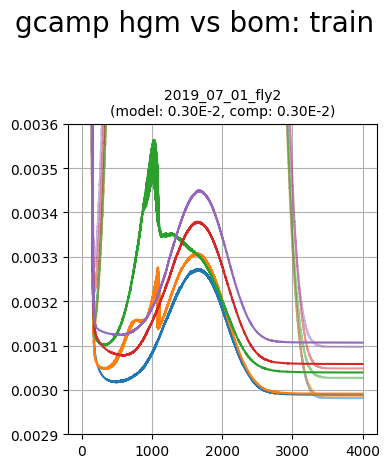

In [23]:
plot_utils.plot_losses_splits(filenames,
							  hgms_losses_train, boms_losses_train,
							  title='gcamp hgm vs bom: train',
							  ylimits=(0.0029, 0.0036))

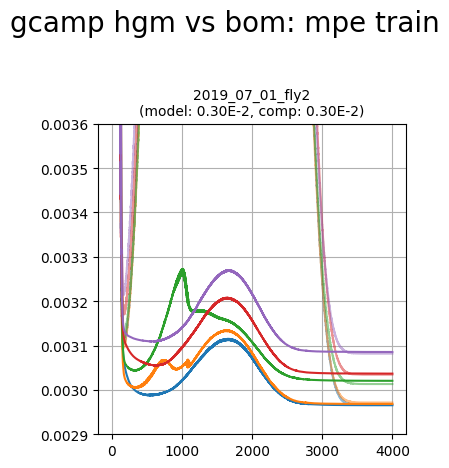

In [24]:
plot_utils.plot_losses_splits(filenames,
							  hgms_mpe_losses_train, boms_mpe_losses_train,
							  title='gcamp hgm vs bom: mpe train',
							  ylimits=(0.0029, 0.0036))

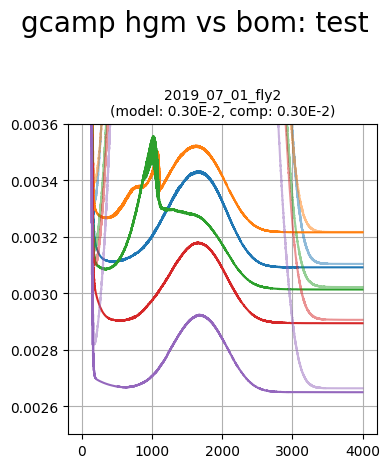

In [17]:
plot_utils.plot_losses_splits(filenames,
							  hgms_losses_test, boms_losses_test,
							  title='gcamp hgm vs bom: test',
							  ylimits=(0.0025, 0.0036))

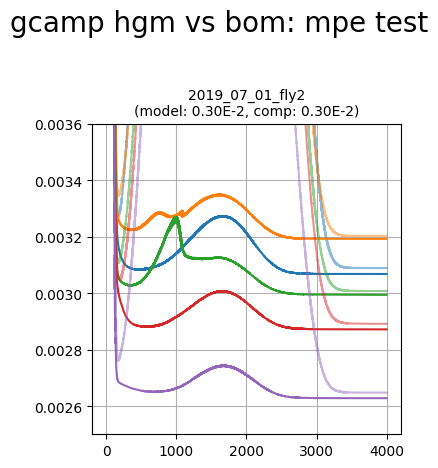

In [18]:
plot_utils.plot_losses_splits(filenames,
							  hgms_mpe_losses_test, boms_mpe_losses_test,
							  title='gcamp hgm vs bom: mpe test',
							  ylimits=(0.0025, 0.0036))